# Práctica de tratamiento de imagen

Cuaderno ejecutado para el análisis de 16 fotografías del mismo objeto. Las celdas de código y sus salidas documentan la carga, el diagnóstico, el tratamiento y la evaluación.

**Entrada:** archivo `a.rar` del repositorio o carga del archivo cuando se solicite.

**Repositorio:** https://github.com/Truder3105/R2-A2-S8-Tarea-documento-Informe-de-resultados-de-tratamiento-de-imagen

In [1]:
# ============ Configuración y librerías ============
import os, re, glob, shutil, subprocess, warnings
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 90, "axes.grid": False, "font.size": 10})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

# --- Parámetros del análisis (se justifican en el informe) ---
CARPETA_IMG     = "imagenes"   # carpeta donde quedan las fotos
UMBRAL_BRILLO   = 80           # separa 'baja iluminación' de 'iluminación ambiente' (ver sección 4)
UMBRAL_SOMBRA   = 30           # intensidad por debajo de la cual un píxel se considera sombra
H_DENOISE       = 6            # fuerza del filtro de reducción de ruido (Non-Local Means)
ID_REFERENCIA   = "I10"        # imagen bien expuesta de la misma cara del objeto (vista posterior)

print("OpenCV:", cv2.__version__, "| NumPy:", np.__version__, "| pandas:", pd.__version__)

OpenCV: 5.0.0 | NumPy: 2.5.4 | pandas: 3.0.1


## Configuración y librerías

In [2]:
# ============ Carga de las imágenes (a.rar -> carpeta imagenes/) ============
EXT = (".jpg", ".jpeg", ".png")
os.makedirs(CARPETA_IMG, exist_ok=True)

def listar_imagenes():
    return sorted(p for p in glob.glob(f"{CARPETA_IMG}/**/*", recursive=True) if p.lower().endswith(EXT))

def extraer_rar(ruta, destino):
    # Intenta con unrar, unar o 7z; si no están, los instala (Colab = Ubuntu)
    def intentar():
        unrar = shutil.which("unrar") or (r"C:\Program Files\WinRAR\UnRAR.exe" if os.name == "nt" and os.path.exists(r"C:\Program Files\WinRAR\UnRAR.exe") else "unrar")
        cmds = [[unrar, "x", "-o+", "-inul", ruta, destino + "/"],
                ["unar", "-q", "-f", "-o", destino, ruta],
                ["7z", "x", "-y", f"-o{destino}", ruta]]
        for c in cmds:
            if shutil.which(c[0]) and subprocess.run(c, capture_output=True).returncode == 0:
                return True
        return False
    if intentar():
        return True
    subprocess.run("apt-get -qq update && apt-get -qq install -y unrar p7zip-full", shell=True, capture_output=True)
    return intentar()

if not listar_imagenes():
    ARCHIVO_LOCAL = r"C:\Users\Truder\Documents\Universidad\2026 - 2\Perecepción Computacional\Fotos\a.rar"
    if not os.path.exists("a.rar") and os.path.exists(ARCHIVO_LOCAL):
        shutil.copy2(ARCHIVO_LOCAL, "a.rar")
    if not os.path.exists("a.rar"):
        try:
            from google.colab import files
            print("Sube el archivo a.rar (o las imágenes sueltas)...")
            subidos = files.upload()
            for nombre in subidos:
                if nombre.lower().endswith(EXT):
                    shutil.move(nombre, os.path.join(CARPETA_IMG, nombre))
        except ImportError:
            raise SystemExit("Coloca a.rar o las imágenes en la carpeta de trabajo.")
    if os.path.exists("a.rar"):
        assert extraer_rar("a.rar", CARPETA_IMG), "No se pudo descomprimir a.rar"

rutas = listar_imagenes()
assert len(rutas) > 0, "No se encontraron imágenes."
print(f"Imágenes encontradas: {len(rutas)}")

# Se cargan una sola vez; identificadores I01..In en orden cronológico (el nombre contiene fecha y hora)
ids  = [f"I{i+1:02d}" for i in range(len(rutas))]
imgs = {i: cv2.imread(r) for i, r in zip(ids, rutas)}     # BGR, uint8
ruta_de = dict(zip(ids, rutas))

Imágenes encontradas: 16


In [3]:
# ============ Inventario técnico ============
filas = []
for i in ids:
    r = ruta_de[i]
    with Image.open(r) as p:
        fmt, modo, (w, h) = p.format, p.mode, p.size
        tiene_exif = bool(p.getexif())
    m = re.search(r"(\d{8})_(\d{6})", os.path.basename(r))
    hora = f"{m.group(2)[:2]}:{m.group(2)[2:4]}:{m.group(2)[4:]}" if m else "-"
    filas.append({"ID": i, "archivo": os.path.basename(r), "formato": fmt, "modo": modo,
                  "ancho": w, "alto": h, "megapíxeles": round(w*h/1e6, 2),
                  "tamaño (KB)": round(os.path.getsize(r)/1024), "hora de captura": hora,
                  "EXIF": "sí" if tiene_exif else "no"})
inv = pd.DataFrame(filas).set_index("ID")
display(inv)
print("\nResoluciones distintas :", inv[["ancho", "alto"]].drop_duplicates().values.tolist())
print("Formatos               :", inv["formato"].unique().tolist(), "| modo:", inv["modo"].unique().tolist())
print("Peso medio por imagen  : %.0f KB  ->  %.2f bits por píxel (compresión JPEG con pérdida)"
      % (inv["tamaño (KB)"].mean(), inv["tamaño (KB)"].mean()*1024*8/(inv['ancho'].iloc[0]*inv['alto'].iloc[0])))

,archivo,formato,modo,ancho,alto,megapíxeles,tamaño (KB),hora de captura,EXIF
ID,,,,,,,,,
I01,20261011_200723.jpg.jpeg,JPEG,RGB,4000,3000,12.0,3049,20:07:23,sí
I02,20261011_200738.jpg.jpeg,JPEG,RGB,4000,3000,12.0,2961,20:07:38,sí
I03,20261011_200801.jpg.jpeg,JPEG,RGB,4000,3000,12.0,3255,20:08:01,sí
I04,20261011_200827.jpg.jpeg,JPEG,RGB,4000,3000,12.0,3166,20:08:27,sí
I05,20261011_200838.jpg.jpeg,JPEG,RGB,4000,3000,12.0,3173,20:08:38,sí
I06,20261011_200857.jpg.jpeg,JPEG,RGB,4000,3000,12.0,3361,20:08:57,sí
I07,20261011_200905.jpg.jpeg,JPEG,RGB,4000,3000,12.0,3489,20:09:05,sí
I08,20261011_200918.jpg.jpeg,JPEG,RGB,4000,3000,12.0,3174,20:09:18,sí
I09,20261011_200929.jpg.jpeg,JPEG,RGB,4000,3000,12.0,4423,20:09:29,sí



Resoluciones distintas : [[4000, 3000]]
Formatos               : ['JPEG'] | modo: ['RGB']
Peso medio por imagen  : 3378 KB  ->  2.31 bits por píxel (compresión JPEG con pérdida)


## Carga de imágenes

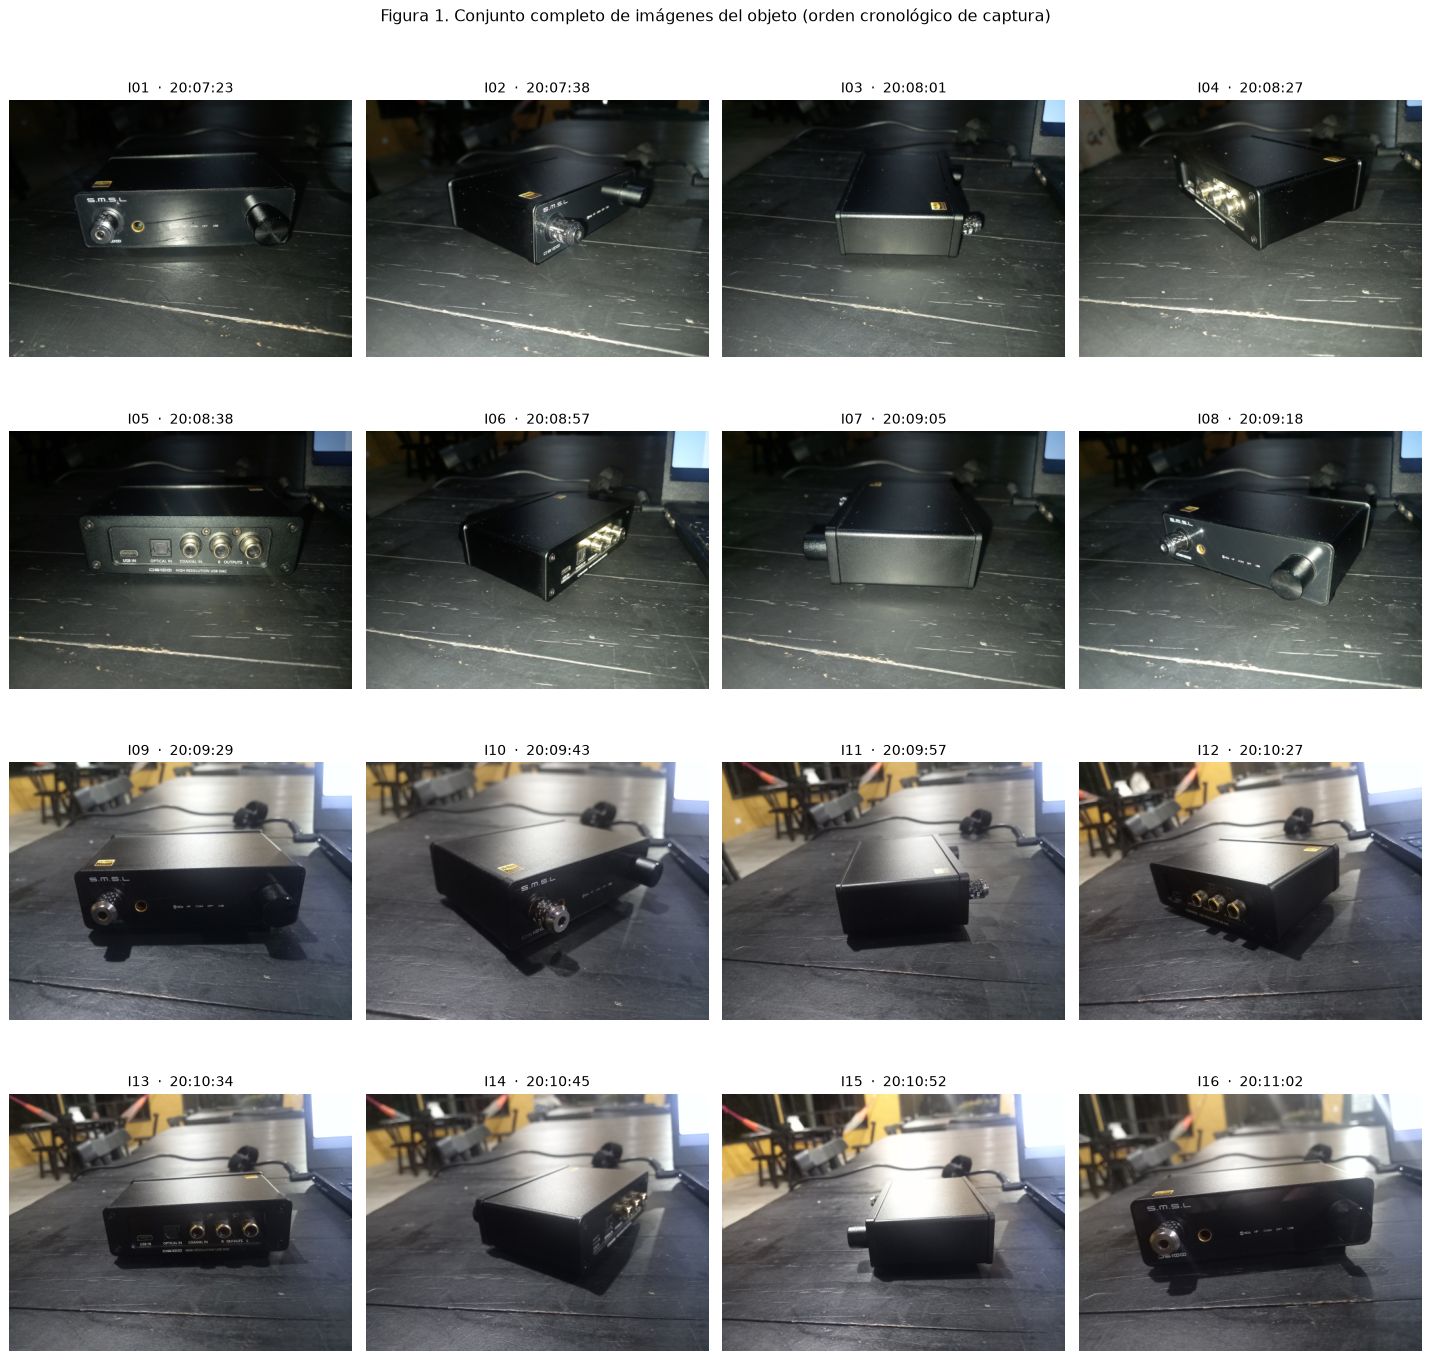

In [4]:
# ============ Mosaico del conjunto completo ============
def a_rgb(bgr, ancho=520):
    h, w = bgr.shape[:2]
    return cv2.cvtColor(cv2.resize(bgr, (ancho, int(h*ancho/w)), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)

n = len(ids); cols = 4; filas_ = int(np.ceil(n/cols))
fig, axs = plt.subplots(filas_, cols, figsize=(16, 3.9*filas_))
for ax in axs.ravel(): ax.axis("off")
for ax, i in zip(axs.ravel(), ids):
    ax.imshow(a_rgb(imgs[i])); ax.set_title(f"{i}  ·  {inv.loc[i, 'hora de captura']}", fontsize=11)
fig.suptitle("Figura 1. Conjunto completo de imágenes del objeto (orden cronológico de captura)", fontsize=13, y=1.0)
plt.tight_layout(); plt.show()

In [5]:
# ============ Métricas de calidad sin referencia ============
def ruido_immerkaer(g):
    # Estimación de la desviación estándar del ruido (Immerkaer, 1996), en niveles de gris
    g = g.astype(np.float64)
    N = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float64)
    c = cv2.filter2D(g, -1, N)[1:-1, 1:-1]
    return float(np.sqrt(np.pi/2) / 6 * np.abs(c).mean())

def histograma_gris(bgr):
    g = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    h = np.bincount(g.ravel(), minlength=256).astype(np.float64)
    return h / h.sum()

def bordes_canny(bgr, sigma=0.33, blur=2.0):
    # Canny con umbrales automáticos a partir de la mediana (técnica de la lectura 'Edge and Contour')
    g = cv2.GaussianBlur(cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY), (0, 0), blur)
    m = float(np.median(g))
    e = cv2.Canny(g, int(max(0, (1-sigma)*m)), int(min(255, (1+sigma)*m)))
    n, _, st, _ = cv2.connectedComponentsWithStats(e, connectivity=8)
    return e, 100*float((e > 0).mean()), int((st[1:, cv2.CC_STAT_AREA] >= 150).sum())

def metricas(bgr):
    g = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    h = histograma_gris(bgr); nz = h[h > 0]
    _, dens, segs = bordes_canny(bgr)
    return {"brillo": g.mean(), "contraste": g.std(),
            "% sombras": 100*(g < UMBRAL_SOMBRA).mean(), "% saturados": 100*(g >= 250).mean(),
            "entropía": float(-(nz*np.log2(nz)).sum()), "ruido σ": ruido_immerkaer(g),
            "nitidez (Lap.)": cv2.Laplacian(g, cv2.CV_64F).var(),
            "bordes %": dens, "segmentos borde": segs}

df = pd.DataFrame({i: metricas(imgs[i]) for i in ids}).T
df["condición"] = np.where(df["brillo"] < UMBRAL_BRILLO, "baja iluminación", "iluminación ambiente")
display(df.round(2))

,brillo,contraste,% sombras,% saturados,entropía,ruido σ,nitidez (Lap.),bordes %,segmentos borde,condición
I01,44.92,40.36,45.70,0.26,6.79,1.13,334.85,1.49,151.0,baja iluminación
I02,64.12,47.02,29.24,0.59,7.28,1.16,180.29,0.65,106.0,baja iluminación
I03,60.82,41.82,28.34,0.36,7.08,1.34,239.20,0.73,73.0,baja iluminación
I04,74.59,48.98,20.59,0.75,7.40,1.18,142.25,0.59,86.0,baja iluminación
I05,49.80,42.01,40.60,0.36,6.87,0.98,245.09,1.73,175.0,baja iluminación
I06,68.54,49.11,25.49,0.56,7.32,1.26,142.89,0.66,85.0,baja iluminación
I07,67.21,46.52,28.97,0.54,7.24,1.85,614.56,1.06,83.0,baja iluminación
I08,73.53,50.12,22.44,0.78,7.43,1.14,121.59,0.60,84.0,baja iluminación
I09,94.37,58.32,15.52,1.86,7.54,3.49,270.21,0.19,24.0,iluminación ambiente
I10,96.60,55.74,11.69,1.58,7.44,0.82,81.33,0.21,29.0,iluminación ambiente


## Inventario técnico

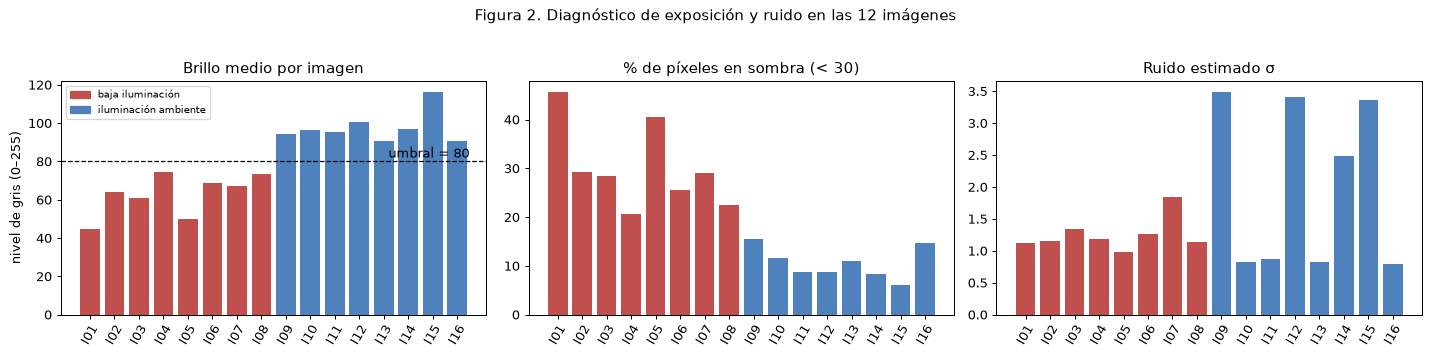

Promedio por grupo (número de imágenes: {'baja iluminación': 8, 'iluminación ambiente': 8})


,brillo,contraste,% sombras,entropía,ruido σ,nitidez (Lap.),bordes %,segmentos borde
condición,,,,,,,,
baja iluminación,62.94,45.74,30.17,7.18,1.25,252.59,0.94,105.38
iluminación ambiente,97.78,58.18,10.63,7.47,2.01,165.53,0.25,31.12


In [6]:
# ============ Figura 2: brillo por imagen y resumen por grupo ============
colores = {"baja iluminación": "#c0504d", "iluminación ambiente": "#4f81bd"}
fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
axs[0].bar(df.index, df["brillo"], color=[colores[c] for c in df["condición"]])
axs[0].axhline(UMBRAL_BRILLO, color="k", ls="--", lw=1); axs[0].text(len(ids)-0.5, UMBRAL_BRILLO+2, f"umbral = {UMBRAL_BRILLO}", ha="right")
axs[0].set_title("Brillo medio por imagen"); axs[0].set_ylabel("nivel de gris (0–255)"); axs[0].tick_params(axis="x", rotation=60)
for ax, col, tit in [(axs[1], "% sombras", "% de píxeles en sombra (< 30)"), (axs[2], "ruido σ", "Ruido estimado σ")]:
    ax.bar(df.index, df[col], color=[colores[c] for c in df["condición"]]); ax.set_title(tit); ax.tick_params(axis="x", rotation=60)
from matplotlib.patches import Patch
axs[0].legend(handles=[Patch(color=v, label=k) for k, v in colores.items()], loc="upper left", fontsize=8)
fig.suptitle("Figura 2. Diagnóstico de exposición y ruido en las 12 imágenes", y=1.03)
plt.tight_layout(); plt.show()

resumen = df.groupby("condición")[["brillo", "contraste", "% sombras", "entropía", "ruido σ", "nitidez (Lap.)", "bordes %", "segmentos borde"]].mean()
print("Promedio por grupo (número de imágenes: %s)" % df["condición"].value_counts().to_dict())
display(resumen.round(2))

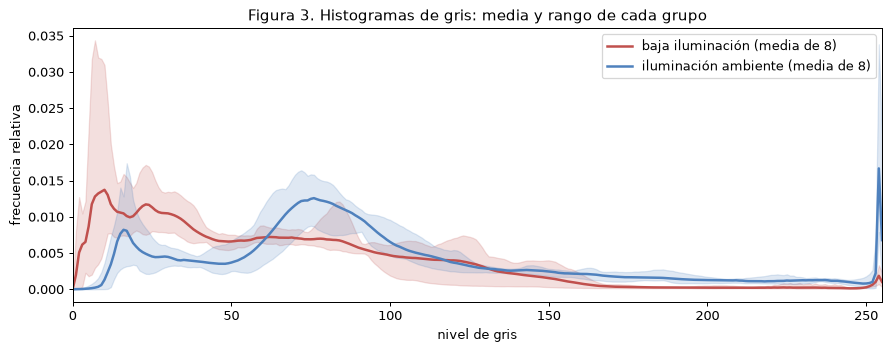

In [7]:
# ============ Figura 3: histogramas de gris por grupo ============
H = {i: histograma_gris(imgs[i]) for i in ids}
x = np.arange(256)
fig, ax = plt.subplots(figsize=(10, 4))
for cond, col in colores.items():
    sel = [i for i in ids if df.loc[i, "condición"] == cond]
    M = np.vstack([H[i] for i in sel])
    ax.fill_between(x, M.min(0), M.max(0), color=col, alpha=0.18)
    ax.plot(x, M.mean(0), color=col, lw=2, label=f"{cond} (media de {len(sel)})")
ax.set_xlim(0, 255); ax.set_xlabel("nivel de gris"); ax.set_ylabel("frecuencia relativa")
ax.set_title("Figura 3. Histogramas de gris: media y rango de cada grupo"); ax.legend()
plt.tight_layout(); plt.show()

## Vista general del conjunto

Imagen con mayor % de sombras : I01 ( 20261011_200723.jpg.jpeg )
Imagen con menor brillo       : I01
Imagen con mayor ruido        : I09
Imagen con menor entropía     : I01


,problemática (I01),referencia (I10)
brillo,44.92,96.60
contraste,40.36,55.74
% sombras,45.70,11.69
entropía,6.79,7.44
ruido σ,1.13,0.82


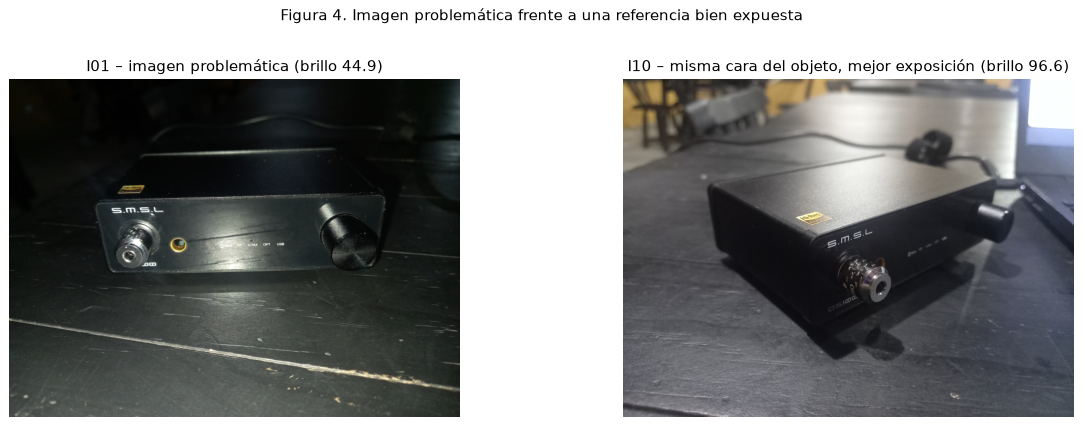

In [8]:
# ============ Selección de la imagen problemática ============
id_prob = df["% sombras"].idxmax()
print("Imagen con mayor % de sombras :", id_prob, "(", ruta_de[id_prob].split(os.sep)[-1], ")")
print("Imagen con menor brillo       :", df["brillo"].idxmin())
print("Imagen con mayor ruido        :", df["ruido σ"].idxmax())
print("Imagen con menor entropía     :", df["entropía"].idxmin())
assert id_prob == df["brillo"].idxmin(), "Los criterios no coinciden; revisar selección."

cmp_ = pd.DataFrame({"problemática (" + id_prob + ")": df.loc[id_prob, ["brillo", "contraste", "% sombras", "entropía", "ruido σ"]],
                     "referencia (" + ID_REFERENCIA + ")": df.loc[ID_REFERENCIA, ["brillo", "contraste", "% sombras", "entropía", "ruido σ"]]}).astype(float)
display(cmp_.round(2))

fig, axs = plt.subplots(1, 2, figsize=(14, 4.6))
axs[0].imshow(a_rgb(imgs[id_prob], 800)); axs[0].set_title(f"{id_prob} – imagen problemática (brillo {df.loc[id_prob,'brillo']:.1f})")
axs[1].imshow(a_rgb(imgs[ID_REFERENCIA], 800)); axs[1].set_title(f"{ID_REFERENCIA} – misma cara del objeto, mejor exposición (brillo {df.loc[ID_REFERENCIA,'brillo']:.1f})")
for a in axs: a.axis("off")
fig.suptitle("Figura 4. Imagen problemática frente a una referencia bien expuesta", y=1.02); plt.tight_layout(); plt.show()

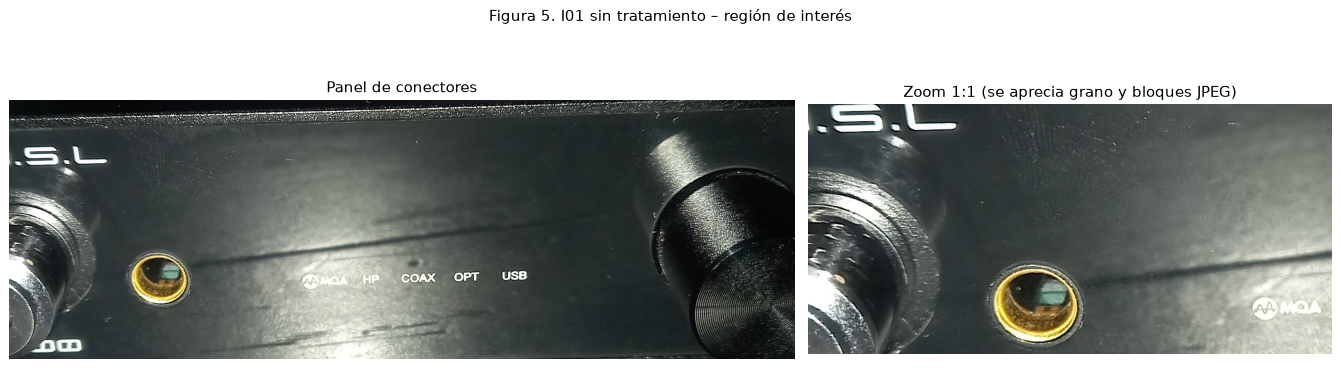

In [9]:
# ============ Zoom a la zona de conectores (ROI) ============
def roi(bgr, x0, x1, y0, y1):
    h, w = bgr.shape[:2]
    return bgr[int(y0*h):int(y1*h), int(x0*w):int(x1*w)]

ROI_PANEL = (0.28, 0.78, 0.34, 0.56)    # panel de conectores (fracciones del ancho/alto)
ROI_ZOOM  = (0.28, 0.50, 0.38, 0.52)    # USB IN + OPTICAL IN + primer RCA, a escala 1:1

fig, axs = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.5, 1]})
axs[0].imshow(cv2.cvtColor(roi(imgs[id_prob], *ROI_PANEL), cv2.COLOR_BGR2RGB)); axs[0].set_title("Panel de conectores")
axs[1].imshow(cv2.cvtColor(roi(imgs[id_prob], *ROI_ZOOM), cv2.COLOR_BGR2RGB)); axs[1].set_title("Zoom 1:1 (se aprecia grano y bloques JPEG)")
for a in axs: a.axis("off")
fig.suptitle(f"Figura 5. {id_prob} sin tratamiento – región de interés", y=1.02); plt.tight_layout(); plt.show()

In [10]:
# ============ Exposición dentro y fuera de la región de interés ============
def mascara_roi(shape, fr=ROI_PANEL):
    h, w = shape[:2]; m = np.zeros((h, w), bool)
    m[int(fr[2]*h):int(fr[3]*h), int(fr[0]*w):int(fr[1]*w)] = True
    return m

def stats_zona(bgr):
    g = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY); m = mascara_roi(g.shape)
    gr = g[m].reshape(int(ROI_PANEL[3]*g.shape[0]) - int(ROI_PANEL[2]*g.shape[0]), -1)   # recorte rectangular del panel
    return {"Panel: brillo": gr.mean(), "Panel: contraste": gr.std(),
            "Panel: % sombras": 100*(gr < UMBRAL_SOMBRA).mean(), "Panel: ruido σ": ruido_immerkaer(gr),
            "Fuera del panel: brillo": g[~m].mean(), "Fuera del panel: % sombras": 100*(g[~m] < UMBRAL_SOMBRA).mean()}

display(pd.Series(stats_zona(imgs[id_prob])).round(2).to_frame(f"{id_prob} original"))

,I01 original
Panel: brillo,77.69
Panel: contraste,56.14
Panel: % sombras,12.52
Panel: ruido σ,2.36
Fuera del panel: brillo,40.87
Fuera del panel: % sombras,49.80


## Métricas de calidad

In [11]:
# ============ Tratamientos candidatos sobre la imagen problemática ============
orig = imgs[id_prob]
B_OBJETIVO = float(df.loc[df["condición"] == "iluminación ambiente", "brillo"].median())
B_ORIG     = float(cv2.cvtColor(orig, cv2.COLOR_BGR2GRAY).mean())
GAMMA      = float(np.log(B_OBJETIVO/255) / np.log(B_ORIG/255))
print(f"Brillo objetivo (mediana del grupo ambiente) = {B_OBJETIVO:.1f}")
print(f"Brillo de {id_prob}                              = {B_ORIG:.1f}")
print(f"Gamma calculada                              = {GAMMA:.3f}")

def aplicar_gamma(bgr, g):
    lut = (255*(np.arange(256)/255)**g).astype(np.uint8)
    return cv2.LUT(bgr, lut)

def reducir_ruido(bgr, h=H_DENOISE):
    return cv2.fastNlMeansDenoisingColored(bgr, None, h, h, 7, 21)

def ecualizar_Y(bgr):
    y = cv2.cvtColor(bgr, cv2.COLOR_BGR2YCrCb); y[..., 0] = cv2.equalizeHist(y[..., 0])
    return cv2.cvtColor(y, cv2.COLOR_YCrCb2BGR)

def clahe_L(bgr, clip=2.0):
    l = cv2.cvtColor(bgr, cv2.COLOR_BGR2LAB); l[..., 0] = cv2.createCLAHE(clip, (8, 8)).apply(l[..., 0])
    return cv2.cvtColor(l, cv2.COLOR_LAB2BGR)

import time; t0 = time.time()
den = reducir_ruido(orig)                      # se calcula una sola vez (es la operación más costosa)
print(f"Reducción de ruido: {time.time()-t0:.1f} s")

candidatos = {
    "Original":                     orig,
    "Ecualización global (Y)":      ecualizar_Y(orig),
    "CLAHE (L)":                    clahe_L(orig),
    "Solo gamma":                   aplicar_gamma(orig, GAMMA),
    "Denoise + gamma (propuesto)":  aplicar_gamma(den, GAMMA),
    "Denoise + gamma + CLAHE 1.5":  clahe_L(aplicar_gamma(den, GAMMA), 1.5),
}

# Histograma medio del grupo bien expuesto (referencia de distribución tonal)
amb_ids = df.index[df["condición"] == "iluminación ambiente"]
H_AMB = np.mean([H[i] for i in amb_ids], axis=0).astype(np.float32)

filas = {}
for k, v in candidatos.items():
    m = metricas(v); h = histograma_gris(v).astype(np.float32)
    m["corr. hist. vs ambiente"] = cv2.compareHist(h, H_AMB, cv2.HISTCMP_CORREL)
    m["Bhattacharyya vs ambiente"] = cv2.compareHist(h, H_AMB, cv2.HISTCMP_BHATTACHARYYA)
    filas[k] = m
tabla = pd.DataFrame(filas).T
fila_amb = df.loc[amb_ids, ["brillo", "contraste", "% sombras", "% saturados", "entropía", "ruido σ", "nitidez (Lap.)", "bordes %", "segmentos borde"]].mean()
tabla.loc["(Referencia: media grupo ambiente)", fila_amb.index] = fila_amb.values
cols = ["brillo", "contraste", "% sombras", "entropía", "ruido σ", "nitidez (Lap.)", "bordes %", "segmentos borde", "corr. hist. vs ambiente", "Bhattacharyya vs ambiente"]
display(tabla[cols].round(3))

Brillo objetivo (mediana del grupo ambiente) = 96.0
Brillo de I01                              = 44.9
Gamma calculada                              = 0.563


Reducción de ruido: 10.8 s


,brillo,contraste,% sombras,entropía,ruido σ,nitidez (Lap.),bordes %,segmentos borde,corr. hist. vs ambiente,Bhattacharyya vs ambiente
Original,44.924,40.365,45.701,6.790,1.126,334.853,1.492,151.000,0.240,0.434
Ecualización global (Y),128.994,72.687,9.135,6.606,2.218,604.559,0.244,31.000,0.007,0.669
CLAHE (L),59.537,44.958,34.221,7.060,2.221,644.131,1.631,157.000,0.576,0.287
Solo gamma,86.431,45.960,6.518,7.269,1.376,310.369,0.427,66.000,0.476,0.287
Denoise + gamma (propuesto),85.575,46.211,8.489,7.286,0.584,252.036,0.419,61.000,0.482,0.287
Denoise + gamma + CLAHE 1.5,89.185,44.288,6.390,7.366,0.904,401.738,0.569,80.000,0.646,0.231
(Referencia: media grupo ambiente),97.775,58.182,10.634,7.472,2.007,165.528,0.255,31.125,NaN,NaN


## Resumen visual por grupo

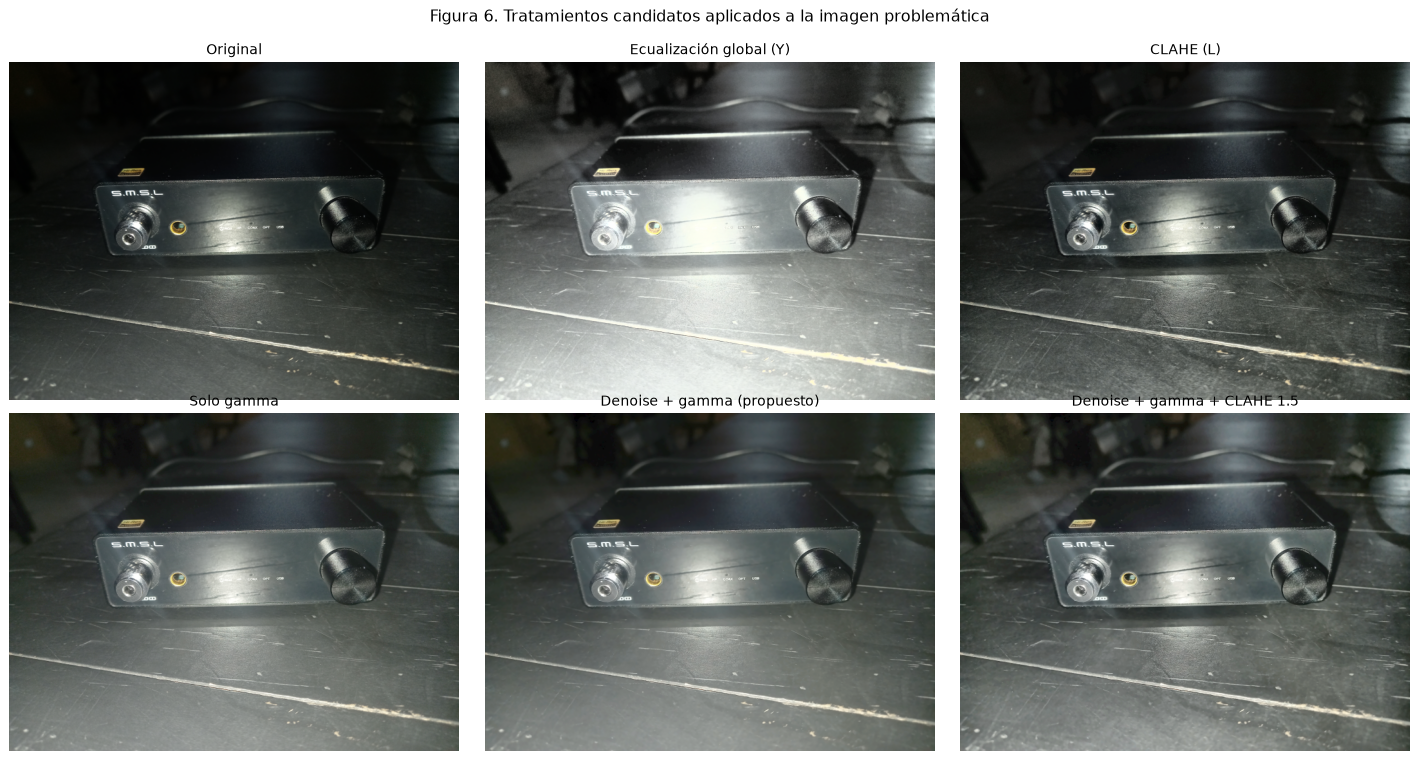

In [12]:
# ============ Figura 6: comparación visual de candidatos ============
fig, axs = plt.subplots(2, 3, figsize=(16, 8.4))
for ax, (k, v) in zip(axs.ravel(), candidatos.items()):
    ax.imshow(a_rgb(v, 700)); ax.set_title(k, fontsize=11); ax.axis("off")
fig.suptitle("Figura 6. Tratamientos candidatos aplicados a la imagen problemática", y=1.0, fontsize=13)
plt.tight_layout(); plt.show()

## Histogramas

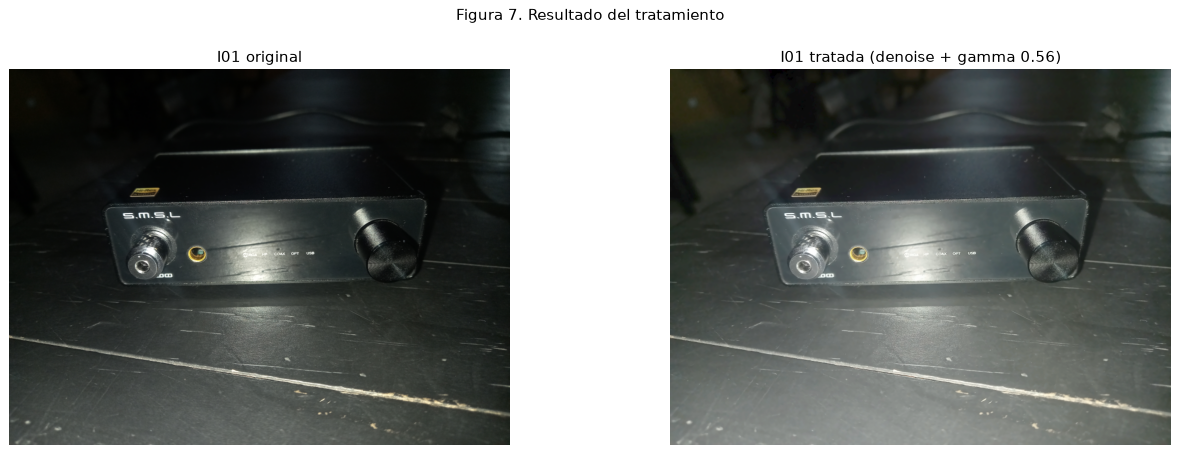

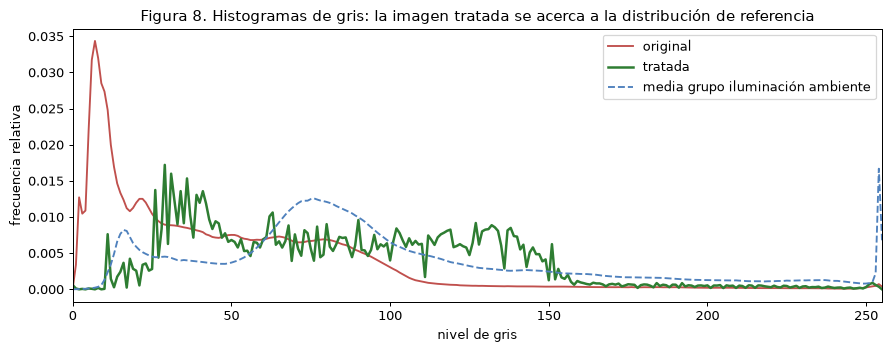

In [13]:
# ============ Resultado final: antes / después ============
final = candidatos["Denoise + gamma (propuesto)"]
os.makedirs("resultados", exist_ok=True)
cv2.imwrite(f"resultados/{id_prob}_tratada.png", final)
cv2.imwrite(f"resultados/{id_prob}_original.png", orig)

fig, axs = plt.subplots(1, 2, figsize=(15, 5))
axs[0].imshow(a_rgb(orig, 900));  axs[0].set_title(f"{id_prob} original")
axs[1].imshow(a_rgb(final, 900)); axs[1].set_title(f"{id_prob} tratada (denoise + gamma {GAMMA:.2f})")
for a in axs: a.axis("off")
fig.suptitle("Figura 7. Resultado del tratamiento", y=1.0); plt.tight_layout(); plt.show()

# Histogramas antes / después frente al grupo bien expuesto
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(x, histograma_gris(orig), color="#c0504d", label="original")
ax.plot(x, histograma_gris(final), color="#2e7d32", lw=2, label="tratada")
ax.plot(x, H_AMB, color="#4f81bd", ls="--", label="media grupo iluminación ambiente")
ax.set_xlim(0, 255); ax.set_xlabel("nivel de gris"); ax.set_ylabel("frecuencia relativa"); ax.legend()
ax.set_title("Figura 8. Histogramas de gris: la imagen tratada se acerca a la distribución de referencia")
plt.tight_layout(); plt.show()

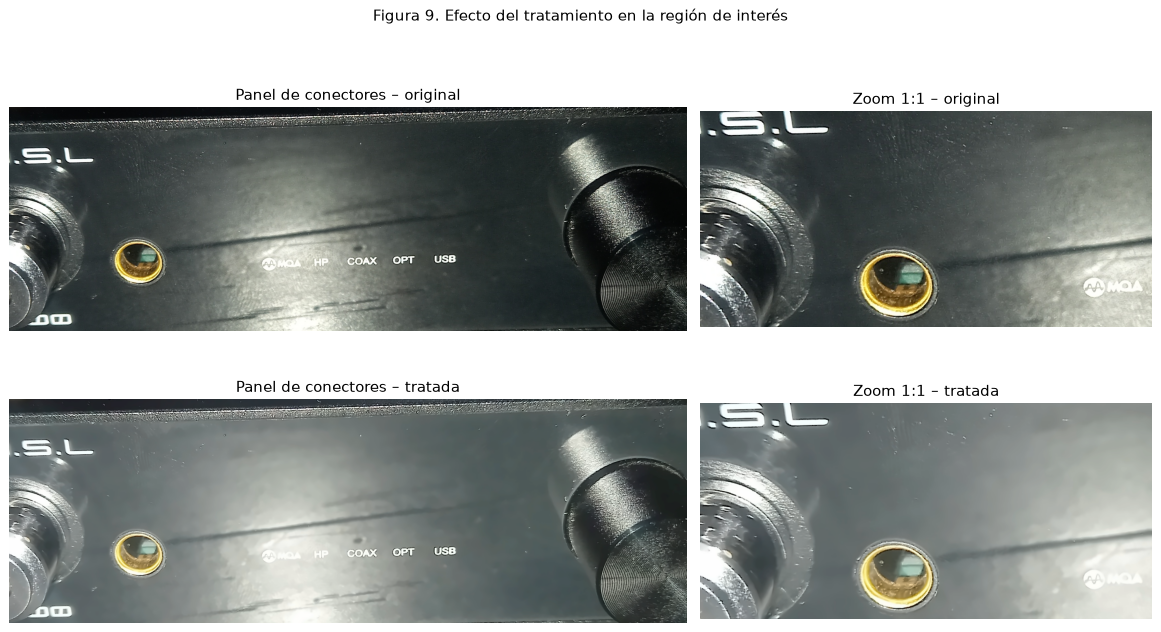

In [14]:
# ============ Figura 9: zona de conectores, antes / después (1:1) ============
fig, axs = plt.subplots(2, 2, figsize=(13, 7.6), gridspec_kw={"width_ratios": [1.5, 1]})
for fila, (tit, im) in enumerate([("original", orig), ("tratada", final)]):
    axs[fila, 0].imshow(cv2.cvtColor(roi(im, *ROI_PANEL), cv2.COLOR_BGR2RGB)); axs[fila, 0].set_title(f"Panel de conectores – {tit}")
    axs[fila, 1].imshow(cv2.cvtColor(roi(im, *ROI_ZOOM), cv2.COLOR_BGR2RGB));  axs[fila, 1].set_title(f"Zoom 1:1 – {tit}")
for a in axs.ravel(): a.axis("off")
fig.suptitle("Figura 9. Efecto del tratamiento en la región de interés", y=1.0); plt.tight_layout(); plt.show()

In [15]:
# ============ Efecto del tratamiento: panel de conectores vs. resto de la imagen ============
zona = pd.DataFrame({"Original": stats_zona(orig), "Tratada": stats_zona(final)})
zona["Cambio"] = zona["Tratada"] - zona["Original"]
zona["Cambio %"] = 100*zona["Cambio"]/zona["Original"]
display(zona.round(2))

,Original,Tratada,Cambio,Cambio %
Panel: brillo,77.69,121.76,44.07,56.73
Panel: contraste,56.14,50.42,-5.72,-10.18
Panel: % sombras,12.52,1.04,-11.49,-91.72
Panel: ruido σ,2.36,1.87,-0.49,-20.81
Fuera del panel: brillo,40.87,81.10,40.23,98.42
Fuera del panel: % sombras,49.80,9.41,-40.39,-81.11


## Selección de imagen problemática

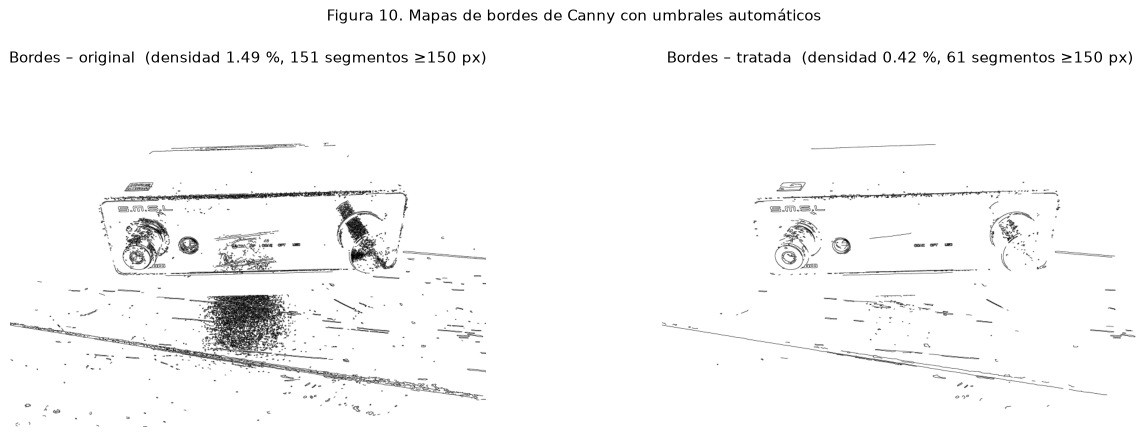

Densidad de bordes en las imágenes bien expuestas: 0.19–0.35 % (media 0.25 %)


In [16]:
# ============ Bordes (Canny) antes / después, como en la lectura 'Edge and Contour' ============
e0, d0, s0 = bordes_canny(orig)
e1, d1, s1 = bordes_canny(final)
def vis_borde(e):   # se dilata un poco para que el trazo sea visible al reducir la imagen
    e = cv2.dilate(e, np.ones((3, 3), np.uint8))
    return cv2.resize(e, (800, int(e.shape[0]*800/e.shape[1])), interpolation=cv2.INTER_AREA)

fig, axs = plt.subplots(1, 2, figsize=(15, 4.8))
axs[0].imshow(vis_borde(e0), cmap="gray_r"); axs[0].set_title(f"Bordes – original  (densidad {d0:.2f} %, {s0} segmentos ≥150 px)")
axs[1].imshow(vis_borde(e1), cmap="gray_r"); axs[1].set_title(f"Bordes – tratada  (densidad {d1:.2f} %, {s1} segmentos ≥150 px)")
for a in axs: a.axis("off")
fig.suptitle("Figura 10. Mapas de bordes de Canny con umbrales automáticos", y=1.0); plt.tight_layout(); plt.show()
dens_amb = df.loc[amb_ids, "bordes %"]
print(f"Densidad de bordes en las imágenes bien expuestas: {dens_amb.min():.2f}–{dens_amb.max():.2f} % (media {dens_amb.mean():.2f} %)")

In [17]:
# ============ Tabla resumen: antes / después / referencia ============
cols_res = ["brillo", "contraste", "% sombras", "entropía", "ruido σ", "bordes %", "segmentos borde", "Bhattacharyya vs ambiente"]
res = tabla.loc[["Original", "Denoise + gamma (propuesto)", "(Referencia: media grupo ambiente)"], cols_res].T
res.columns = ["Original", "Tratada", "Referencia (grupo ambiente)"]
res["Cambio"] = res["Tratada"] - res["Original"]
display(res.round(3))

,Original,Tratada,Referencia (grupo ambiente),Cambio
brillo,44.924,85.575,97.775,40.651
contraste,40.365,46.211,58.182,5.846
% sombras,45.701,8.489,10.634,-37.212
entropía,6.790,7.286,7.472,0.496
ruido σ,1.126,0.584,2.007,-0.541
bordes %,1.492,0.419,0.255,-1.073
segmentos borde,151.000,61.000,31.125,-90.000
Bhattacharyya vs ambiente,0.434,0.287,NaN,-0.146


In [18]:
# ============ Pipeline aplicado a todo el grupo de baja iluminación ============
def tratar(bgr, brillo_objetivo=B_OBJETIVO, denoised=None):
    b = float(cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY).mean())
    g = float(np.log(brillo_objetivo/255) / np.log(b/255))
    d = denoised if denoised is not None else reducir_ruido(bgr)
    return aplicar_gamma(d, g), g

oscuras = list(df.index[df["condición"] == "baja iluminación"])
tratadas, filas = {}, []
for i in oscuras:
    t, g = tratar(imgs[i], denoised=den if i == id_prob else None)
    tratadas[i] = t
    a, d = df.loc[i], metricas(t)
    filas.append({"ID": i, "γ": round(g, 2),
                  "brillo antes": a["brillo"], "brillo después": d["brillo"],
                  "% sombras antes": a["% sombras"], "% sombras después": d["% sombras"],
                  "ruido antes": a["ruido σ"], "ruido después": d["ruido σ"],
                  "entropía antes": a["entropía"], "entropía después": d["entropía"]})
verif = pd.DataFrame(filas).set_index("ID")
display(verif.round(2))
print("\nPromedio del grupo:")
display(verif.drop(columns="γ").mean().round(2).to_frame("media").T)
print("Referencia grupo ambiente -> brillo %.1f | %% sombras %.1f | ruido %.2f | entropía %.2f"
      % tuple(df.loc[amb_ids, ["brillo", "% sombras", "ruido σ", "entropía"]].mean()))

,γ,brillo antes,brillo después,% sombras antes,% sombras después,ruido antes,ruido después,entropía antes,entropía después
ID,,,,,,,,,
I01,0.56,44.92,85.58,45.70,8.49,1.13,0.58,6.79,7.29
I02,0.71,64.12,89.24,29.24,12.21,1.16,0.37,7.28,7.44
I03,0.68,60.82,89.94,28.34,3.98,1.34,0.39,7.08,7.24
I04,0.79,74.59,91.44,20.59,10.75,1.18,0.33,7.40,7.40
I05,0.60,49.80,86.33,40.60,11.12,0.98,0.50,6.87,7.27
I06,0.74,68.54,90.12,25.49,9.88,1.26,0.32,7.32,7.42
I07,0.73,67.21,90.25,28.97,7.26,1.85,0.89,7.24,7.32
I08,0.79,73.53,91.02,22.44,10.79,1.14,0.29,7.43,7.50



Promedio del grupo:


,brillo antes,brillo después,% sombras antes,% sombras después,ruido antes,ruido después,entropía antes,entropía después
media,62.94,89.24,30.17,9.31,1.25,0.46,7.18,7.36


Referencia grupo ambiente -> brillo 97.8 | % sombras 10.6 | ruido 2.01 | entropía 7.47


## Región de interés

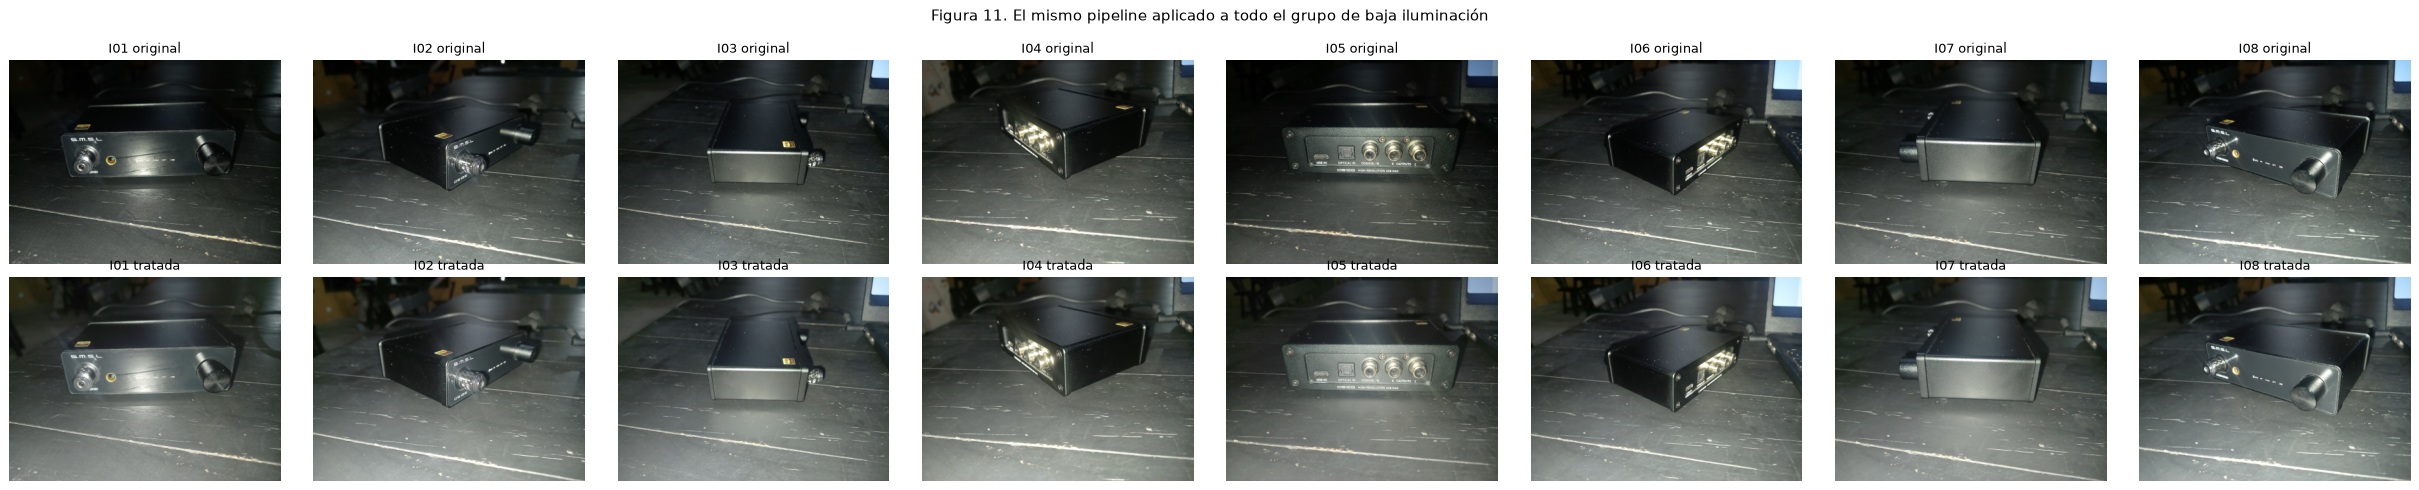

In [19]:
# ============ Figura 11: antes / después de las seis imágenes oscuras ============
fig, axs = plt.subplots(2, len(oscuras), figsize=(3.4*len(oscuras), 5.4))
for j, i in enumerate(oscuras):
    axs[0, j].imshow(a_rgb(imgs[i], 420)); axs[0, j].set_title(f"{i} original", fontsize=10)
    axs[1, j].imshow(a_rgb(tratadas[i], 420)); axs[1, j].set_title(f"{i} tratada", fontsize=10)
for a in axs.ravel(): a.axis("off")
fig.suptitle("Figura 11. El mismo pipeline aplicado a todo el grupo de baja iluminación", y=1.0); plt.tight_layout(); plt.show()

## Medición por zonas

In [20]:
# ============ Versiones de las librerías (reproducibilidad) ============
import sys
print("Python  :", sys.version.split()[0])
print("OpenCV  :", cv2.__version__)
print("NumPy   :", np.__version__)
print("pandas  :", pd.__version__)

Python  : 3.12.14
OpenCV  : 5.0.0
NumPy   : 2.5.4
pandas  : 3.0.1
